Étape 1 : Configuration et Connexion à la Base SQLite

In [18]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Connexion au fichier SQLite local
conn = sqlite3.connect('analysis.db')

# Définition du thème visuel épuré et professionnel avec Seaborn
sns.set_theme(style='whitegrid')

Étape 2 : Création des 5 Graphiques Métier & Insights

2. Graphique 1 : Tendance au fil du temps (Lignes)

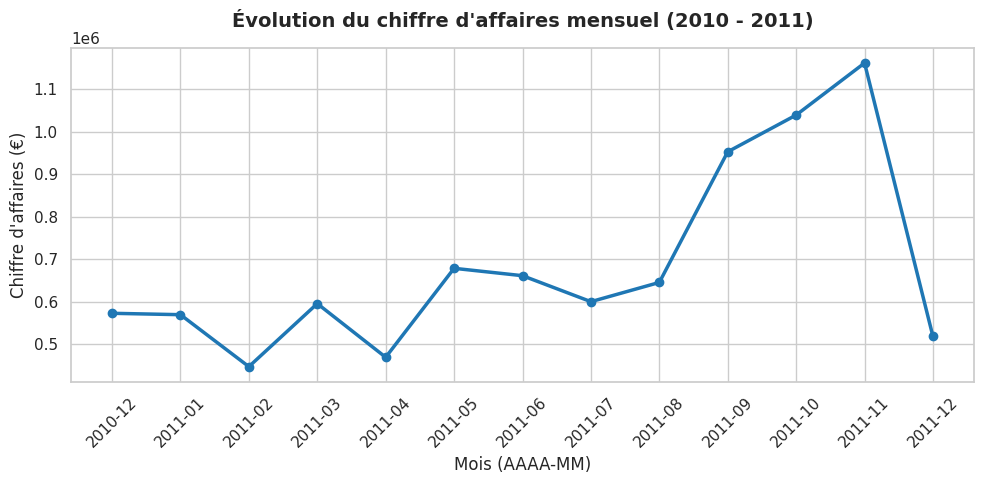

In [23]:
# Requête SQL pour la tendance temporelle
df_monthly = pd.read_sql("""
    SELECT Month, SUM(TotalPrice) AS TotalSales
    FROM sales
    GROUP BY Month
    ORDER BY Month
""", conn)

# Création du graphique de lignes
plt.figure(figsize=(10, 5))
plt.plot(df_monthly['Month'], df_monthly['TotalSales'], marker='o', color='#1f77b4', linewidth=2.5)

# Formatage professionnel
plt.title("Évolution du chiffre d'affaires mensuel (2010 - 2011)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Mois (AAAA-MM)", fontsize=12)
plt.ylabel("Chiffre d'affaires (€)", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

3. Graphique 2 : Comparaison des catégories (Barres)

/tmp/ipykernel_604/3848702577.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_country, x='Country', y='TotalSales', palette='Blues_r')


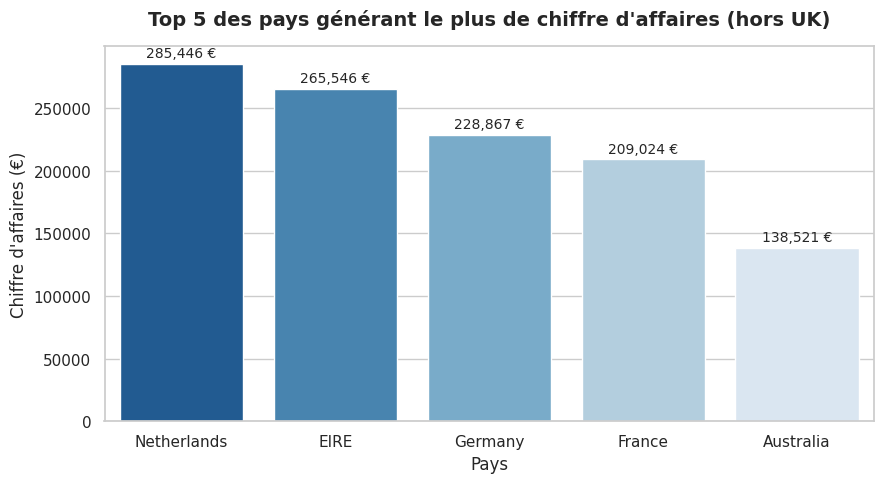

In [24]:
# Requête SQL pour comparer les pays (hors UK)
df_country = pd.read_sql("""
    SELECT Country, SUM(TotalPrice) AS TotalSales
    FROM sales
    WHERE Country != 'United Kingdom'
    GROUP BY Country
    ORDER BY TotalSales DESC
    LIMIT 5
""", conn)

# Création du graphique à barres
plt.figure(figsize=(9, 5))
sns.barplot(data=df_country, x='Country', y='TotalSales', palette='Blues_r')

# Formatage professionnel et annotations
plt.title("Top 5 des pays générant le plus de chiffre d'affaires (hors UK)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Pays", fontsize=12)
plt.ylabel("Chiffre d'affaires (€)", fontsize=12)

for index, row in df_country.iterrows():
    plt.text(index, row['TotalSales'] + 5000, f"{row['TotalSales']:,.0f} €", ha='center', fontsize=10)

plt.tight_layout()
plt.show()

4. Graphique 3 : Distribution (Histogramme)

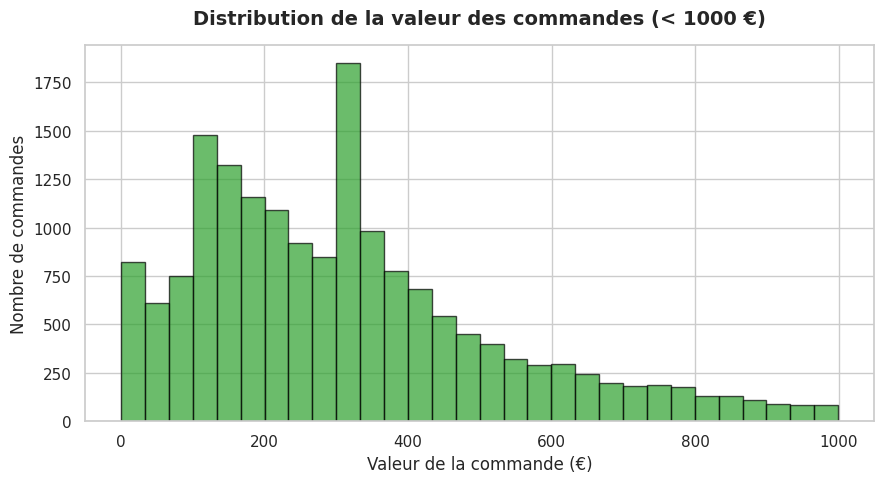

In [25]:
# Requête SQL pour la distribution du montant des commandes
df_invoices = pd.read_sql("""
    SELECT InvoiceNo, SUM(TotalPrice) AS InvoiceValue
    FROM sales
    GROUP BY InvoiceNo
    HAVING InvoiceValue > 0 AND InvoiceValue < 1000
""", conn)

# Création de l'histogramme[cite: 10]
plt.figure(figsize=(9, 5))
plt.hist(df_invoices['InvoiceValue'], bins=30, color='#2ca02c', edgecolor='black', alpha=0.7)

# Formatage professionnel[cite: 10]
plt.title("Distribution de la valeur des commandes (< 1000 €)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Valeur de la commande (€)", fontsize=12)
plt.ylabel("Nombre de commandes", fontsize=12)
plt.tight_layout()
plt.show()

5. Graphique 4 : Relation (Nuage de points)

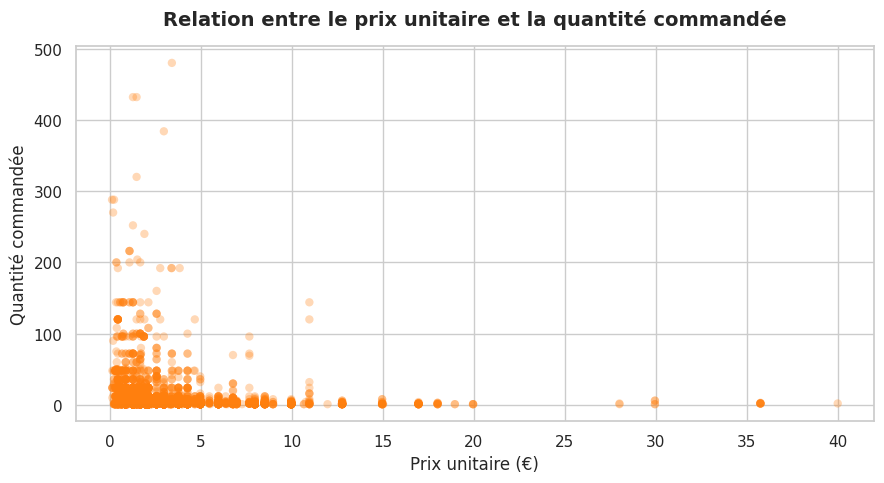

In [26]:
# Requête SQL pour la relation Prix Unitaire vs Quantité
df_scatter = pd.read_sql("""
    SELECT Quantity, UnitPrice
    FROM sales
    WHERE Quantity > 0 AND Quantity < 500 AND UnitPrice > 0 AND UnitPrice < 50
    LIMIT 5000
""", conn)

# Création du nuage de points[cite: 10]
plt.figure(figsize=(9, 5))
plt.scatter(df_scatter['UnitPrice'], df_scatter['Quantity'], alpha=0.3, color='#ff7f0e', edgecolors='none')

# Formatage professionnel[cite: 10]
plt.title("Relation entre le prix unitaire et la quantité commandée", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Prix unitaire (€)", fontsize=12)
plt.ylabel("Quantité commandée", fontsize=12)
plt.tight_layout()
plt.show()

6. Graphique 5 : Composition (Graphique circulaire)

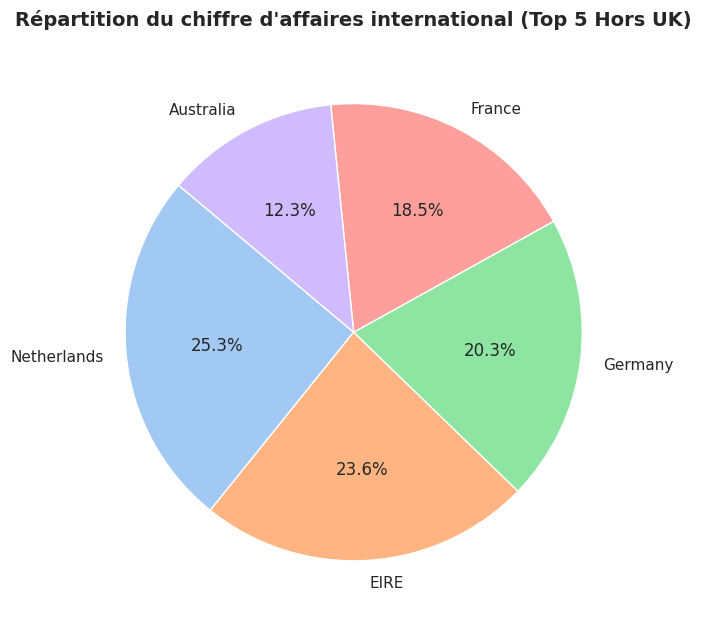

In [27]:
# Création du graphique circulaire (5 catégories max)[cite: 10]
plt.figure(figsize=(7, 7))
plt.pie(df_country['TotalSales'], labels=df_country['Country'], autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel')[0:5])

# Formatage professionnel[cite: 10]
plt.title("Répartition du chiffre d'affaires international (Top 5 Hors UK)", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()